In [ ]:
"""Compare C_l^EE and the dummy C_l^XX, which should be exactly equal"""
import numpy as np
from classy import Class

cosmo = Class()
cosmo.set({
    "output": "tCl,pCl",      # polarization needed for EE and XX
    "l_max_scalars": 2500, "hierarchy" : "TAM"
})
cosmo.compute()

cl = cosmo.raw_cl(2500)       # unlensed, dimensionless C_l (no T_cmb^2 factor)
ell = cl["ell"][2:]
ee, xx = cl["ee"][2:], cl["xx"][2:] #Drop l = 0 ,1 so it doesn't divide by zero

#compare EE and XX
abs_diff = xx - ee
with np.errstate(divide="ignore", invalid="ignore"):
    rel_diff = np.where(ee != 0, abs_diff / ee, 0.0) #chat reccomended this to avoid divide by zero warning

print(f"max |XX-EE|          = {np.max(np.abs(abs_diff)):.3e}")
print(f"max |XX-EE|/EE       = {np.max(np.abs(rel_diff)):.3e}")
print(f"np.allclose(EE, XX)  = {np.allclose(ee, xx, rtol=1e-12, atol=0)}")
print(f"identical            = {np.array_equal(ee, xx)}") 



max |XX-EE|          = 0.000e+00
max |XX-EE|/EE       = 0.000e+00
np.allclose(EE, XX)  = True
identical            = True


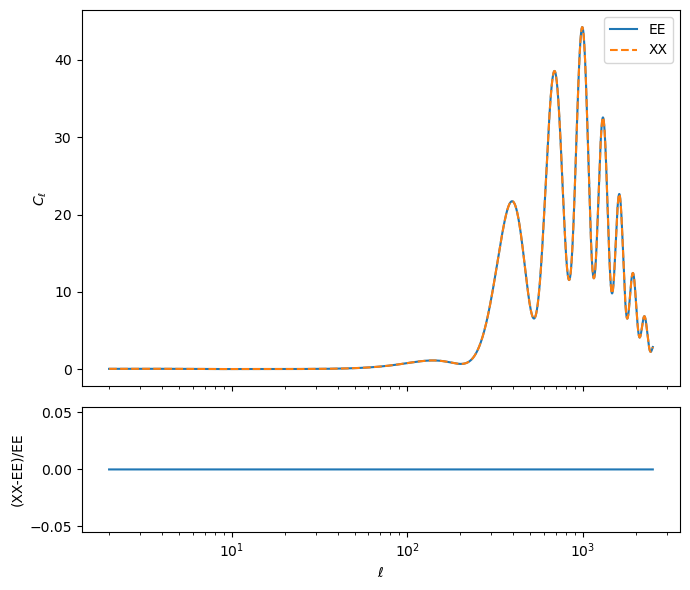

In [5]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

fac = ell * (ell + 1) / (2 * np.pi) * (cosmo.T_cmb() * 1e6) ** 2  # muK^2 factor

#plot EE over XX and a "residual" plot of (XX-EE)/EE
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.plot(ell, fac * ee, label="EE")
a1.plot(ell, fac * xx, "--", label="XX")
a1.set_ylabel(r"$C_\ell$")
a1.set_xscale("log")
a1.legend()

a2.plot(ell, rel_diff)
a2.set_xlabel(r"$\ell$")
a2.set_ylabel("(XX-EE)/EE")
fig.tight_layout()
plt.show()


In [ ]:
cosmo.struct_cleanup()
cosmo.empty()

In [7]:
print(xx)
print(ee)

[4.37294873e-15 2.80167962e-15 1.45344703e-15 ... 3.82879947e-19
 3.84255079e-19 3.85641824e-19]
[4.37294873e-15 2.80167962e-15 1.45344703e-15 ... 3.82879947e-19
 3.84255079e-19 3.85641824e-19]
